# Tahap 2B: Diferensiasi Biasa & Musiman, Uji Ulang Stasioneritas, serta Penentuan Orde ($d, D$)
**Penanggung Jawab:** Michael Christian S. G. (L0224035)  
**Mata Kuliah:** Analisis Data Timeseries (12023130325), 3 SKS, Semester 5  
**Program Studi:** Sains Data, Universitas Sebelas Maret  

---

### Tujuan & Ruang Lingkup Pengerjaan (Tahap 2B):
Sesuai dengan panduan penugasan dan kelanjutan dari **Tahap 1 (Kunto)** serta **Tahap 2A (Maulana)**:
1. **Diferensiasi Biasa & Musiman:**
   - Melakukan diferensiasi biasa orde pertama ($d = 1$) dan orde kedua ($d = 2$).
   - Melakukan diferensiasi musiman tahunan ($D = 1, s = 52$) serta diferensiasi ganda biasa + musiman ($d = 1, D = 1$).
   - Menerapkan pengujian baik pada **Deret Asli** (Opsi 1 / Baseline) maupun **Deret Logaritma** (Opsi 2 / Alternatif).
2. **Uji Ulang Formal Stasioneritas (ADF & KPSS):**
   - Menguji ulang stasioneritas rataan pada setiap deret diferensiasi menggunakan dua uji komplementer:
     * **ADF (Augmented Dickey-Fuller):** Menguji keberadaan akar unit ($H_0$: unit root / tidak stasioner).
     * **KPSS (Kwiatkowski-Phillips-Schmidt-Shin):** Menguji stasioneritas di sekitar konstan ($H_0$: stasioner).
   - Melakukan konfirmasi silang (*cross-confirmation*) pada data latih ($n=104$) dan data penuh ($n=116$).
3. **Investigasi Mendalam & Kewaspadaan Terhadap Over-Differencing:**
   - Memeriksa bahaya *over-differencing* menggunakan tiga kriteria diagnostik baku Box-Jenkins:
     * **Kriteria Perubahan Varians Deret:** Membandingkan $\text{Var}(y_t)$ terhadap $\text{Var}(\Delta^k y_t)$ dan $\text{Var}(\Delta_{52} y_t)$.
     * **Kriteria Autokorelasi Lag 1 ($r_1$):** Mengidentifikasi kemunculan akar MA semu bila $r_1 \approx -0,50$ atau lebih negatif ($r_1 < -0,50$).
     * **Kriteria Kehilangan Derajat Kebebasan (*Sample Size Loss*):** Menilai dampak pemotongan 52 pengamatan pada diferensiasi musiman $s=52$ terhadap data latih ($n=104$).
     * **Bukti Empiris Model SARIMA:** Membandingkan performa empiris model dengan $D=1$ vs $D=0$ pada data uji.
4. **Keputusan Final Penentuan Nilai $d$ dan $D$:**
   - Menetapkan nilai $d$ dan $D$ definitif disertai justifikasi statistik, visual, dan kelayakan peramalan untuk dilanjutkan ke tahap pemodelan ARIMA/SARIMA berikutnya.


In [1]:
# ==============================================================================
# 1. SETUP LINGKUNGAN DAN IMPORT LIBRARY
# ==============================================================================
import warnings
from pathlib import Path
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

warnings.filterwarnings("ignore")

# Penentuan Path Direktori
ROOT = Path.cwd().resolve()
if (ROOT / "data" / "processed").exists():
    DATA_DIR = ROOT / "data" / "processed"
    OUT_DIR = ROOT / "outputs"
elif (ROOT.parent / "data" / "processed").exists():
    DATA_DIR = ROOT.parent / "data" / "processed"
    OUT_DIR = ROOT.parent / "outputs"
else:
    DATA_DIR = Path(r"D:/Kuliah/Semester 5/timeseries/adt-project/data/processed")
    OUT_DIR = Path(r"D:/Kuliah/Semester 5/timeseries/adt-project/outputs")

FIG_DIR = OUT_DIR / "figures"
TAB_DIR = OUT_DIR / "tables"
FIG_DIR.mkdir(parents=True, exist_ok=True)
TAB_DIR.mkdir(parents=True, exist_ok=True)

# Konfigurasi Visualisasi Standar Publikasi
plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({
    "figure.dpi": 120,
    "savefig.dpi": 300,
    "font.size": 10,
    "axes.titlesize": 11,
    "axes.labelsize": 10,
    "legend.fontsize": 9,
    "axes.grid": True,
    "grid.alpha": 0.35,
    "figure.autolayout": True
})

# Palet Warna Konsisten Tim
COLORS = {
    "blue": "#1f77b4",
    "orange": "#ff7f0e",
    "green": "#2ca02c",
    "red": "#d62728",
    "purple": "#9467bd",
    "gray": "#7f7f7f",
    "teal": "#17becf"
}

print(f"Direktori data   : {DATA_DIR}")
print(f"Direktori output : {OUT_DIR}")


Direktori data   : D:\Kuliah\Semester 5\timeseries\adt-project\data\processed
Direktori output : D:\Kuliah\Semester 5\timeseries\adt-project\outputs


In [2]:
# ==============================================================================
# 2. PEMUATAN DATA DAN PARTISI LATIH-UJI
# ==============================================================================
# Memuat data mingguan PM2.5 model CAMS Surakarta hasil pra-pemrosesan Kunto
df_raw = pd.read_csv(DATA_DIR / "pm25_surakarta_weekly_model.csv", parse_dates=["week_start"])
series = df_raw.set_index("week_start")["pm25"].asfreq("7D")

# Partisi Latih-Uji: 104 minggu latih (2 siklus musiman m=52) dan 12 minggu uji
train = series.iloc[:-12]
test = series.iloc[-12:]

# Versi Logaritma (mengacu pada Opsi 2 Tahap 2A)
series_log = np.log(series)
train_log = np.log(train)
test_log = np.log(test)

SEASON = 52

print("=" * 70)
print("RINGKASAN PARTISI DATA DERET WAKTU PM2.5 KOTA SURAKARTA")
print("=" * 70)
print(f"Total deret penuh (N)   : {len(series)} minggu ({series.index.min().strftime('%Y-%m-%d')} s.d. {series.index.max().strftime('%Y-%m-%d')})")
print(f"Data latih / in-sample  : {len(train)} minggu ({train.index.min().strftime('%Y-%m-%d')} s.d. {train.index.max().strftime('%Y-%m-%d')}) [2 siklus penuh]")
print(f"Data uji / out-of-sample: {len(test)} minggu ({test.index.min().strftime('%Y-%m-%d')} s.d. {test.index.max().strftime('%Y-%m-%d')})")
print(f"Frekuensi musiman (s)   : {SEASON} minggu/tahun")
print("=" * 70)


RINGKASAN PARTISI DATA DERET WAKTU PM2.5 KOTA SURAKARTA
Total deret penuh (N)   : 116 minggu (2022-08-08 s.d. 2024-10-21)
Data latih / in-sample  : 104 minggu (2022-08-08 s.d. 2024-07-29) [2 siklus penuh]
Data uji / out-of-sample: 12 minggu (2024-08-05 s.d. 2024-10-21)
Frekuensi musiman (s)   : 52 minggu/tahun


## 1. Formulasi Matematis Diferensiasi Biasa dan Musiman

Dalam metodologi Box-Jenkins, deret waktu non-stasioner pada level rata-rata diubah menjadi stasioner menggunakan operator diferensiasi (*backshift operator* $B$, di mana $B^k y_t = y_{t-k}$):

1. **Diferensiasi Biasa Orde 1 ($d = 1$):**
   $$\Delta y_t = (1 - B) y_t = y_t - y_{t-1}$$
   Berfungsi untuk mengeliminasi tren linier atau *stochastic drift* (akar unit reguler). Pengamatan efektif berkurang $1$ titik ($n - 1$).

2. **Diferensiasi Biasa Orde 2 ($d = 2$):**
   $$\Delta^2 y_t = (1 - B)^2 y_t = \Delta(\Delta y_t) = y_t - 2y_{t-1} + y_{t-2}$$
   Digunakan jika deret memiliki tren kuadratik atau bila diferensiasi pertama masih menyisakan akar unit. Pengamatan efektif berkurang $2$ titik ($n - 2$).

3. **Diferensiasi Musiman Orde 1 ($D = 1, s = 52$):**
   $$\Delta_{52} y_t = (1 - B^{52}) y_t = y_t - y_{t-52}$$
   Berfungsi untuk mengeliminasi ketidakstasioneran musiman (*seasonal unit root*). Pengamatan efektif berkurang $52$ titik ($n - 52$).

4. **Diferensiasi Ganda Biasa & Musiman ($d = 1, D = 1, s = 52$):**
   $$\Delta \Delta_{52} y_t = (1 - B)(1 - B^{52}) y_t = y_t - y_{t-1} - y_{t-52} + y_{t-53}$$
   Mengeliminasi tren stokastik sekaligus pola musiman non-stasioner. Pengamatan efektif berkurang $53$ titik ($n - 53$).

---
> [!WARNING]
> **Catatan Kritis Ukuran Sampel Mingguan:**  
> Pada data latih kita yang berjumlah $n = 104$ minggu (tepat 2 siklus tahunan $s = 52$), penerapan diferensiasi musiman $D = 1$ membuang $52$ pengamatan awal ($50\%$ data hilang!). Observasi efektif yang tersisa hanya $52$ minggu ($1$ siklus tunggal). Kondisi ini sangat rentan menimbulkan **over-differencing musiman**, ketidakstabilan estimasi parameter, serta matrik kovarians singular.


In [3]:
# ==============================================================================
# 3. KOMPUTASI DERET DIFERENSIASI DAN STATISTIK DESKRIPTIF
# ==============================================================================

def generate_differenced_dict(ts_data, is_log=False):
    prefix = "ln_" if is_log else ""
    return {
        f"{prefix}Level (d=0, D=0)": ts_data,
        f"{prefix}Diferensiasi Biasa 1 (d=1, D=0)": ts_data.diff(1).dropna(),
        f"{prefix}Diferensiasi Biasa 2 (d=2, D=0)": ts_data.diff(1).diff(1).dropna(),
        f"{prefix}Diferensiasi Musiman (d=0, D=1, s=52)": ts_data.diff(SEASON).dropna(),
        f"{prefix}Diferensiasi Ganda (d=1, D=1, s=52)": ts_data.diff(1).diff(SEASON).dropna()
    }

# Komputasi pada data latih (train) deret asli
diff_train_original = generate_differenced_dict(train, is_log=False)
# Komputasi pada data latih (train) deret log
diff_train_log = generate_differenced_dict(train_log, is_log=True)

# Tabel Ringkasan Statistik Deskriptif untuk Deret Asli (Train)
desc_rows = []
for name, s in diff_train_original.items():
    desc_rows.append({
        "Deret / Orde": name,
        "N Efektif": len(s),
        "N Hilang": len(train) - len(s),
        "Mean": round(s.mean(), 4),
        "Std Dev": round(s.std(), 4),
        "Varians": round(s.var(), 4),
        "Min": round(s.min(), 4),
        "Max": round(s.max(), 4),
        "Skewness": round(s.skew(), 4),
        "Kurtosis": round(s.kurtosis(), 4)
    })

df_desc_diff = pd.DataFrame(desc_rows)
display(df_desc_diff)


,Deret / Orde,N Efektif,N Hilang,Mean,Std Dev,Varians,Min,Max,Skewness,Kurtosis
0,"Level (d=0, D=0)",104,0,24.6174,8.4207,70.9086,9.6917,47.2560,0.5405,-0.4238
1,"Diferensiasi Biasa 1 (d=1, D=0)",103,1,-0.0654,8.4736,71.8018,-23.8560,27.5863,0.2559,1.0062
2,"Diferensiasi Biasa 2 (d=2, D=0)",102,2,-0.0165,13.9136,193.5871,-33.3155,37.4595,0.1022,0.3383
3,"Diferensiasi Musiman (d=0, D=1, s=52)",52,52,-2.1456,9.2462,85.4917,-20.3327,16.9583,-0.0329,-0.6636
4,"Diferensiasi Ganda (d=1, D=1, s=52)",51,53,-0.0947,11.0027,121.0598,-25.4250,19.7018,-0.2505,-0.5146


## 2. Analisis Visual Deret Hasil Diferensiasi

Pemeriksaan visual merupakan langkah awal yang diwajibkan sebelum pengujian statistik formal. Ciri visual deret yang telah mencapai kestasioneran rataan:
1. **Fluktuasi di Sekitar Rata-rata Konstan:** Deret bergerak horizontal di sekitar garis nol tanpa adanya pergeseran rataan (*no mean drift* atau tren jangka panjang).
2. **Amplitudo Relatif Seragam:** Variabilitas data berada pada pita yang relatif terkontrol sepanjang waktu.
3. **Pembedaan Visual Terhadap Over-Differencing:**
   - Deret yang ter-diferensiasi secara tepat ($d = 1$) memperlihatkan osilasi alami yang stabil di sekitar nol.
   - Deret yang mengalami *over-differencing* ($d = 2$) menunjukkan osilasi buatan yang sangat kasar, tajam, dan memantul bolak-balik antara nilai positif ekstrem dan negatif ekstrem secara terus-menerus.


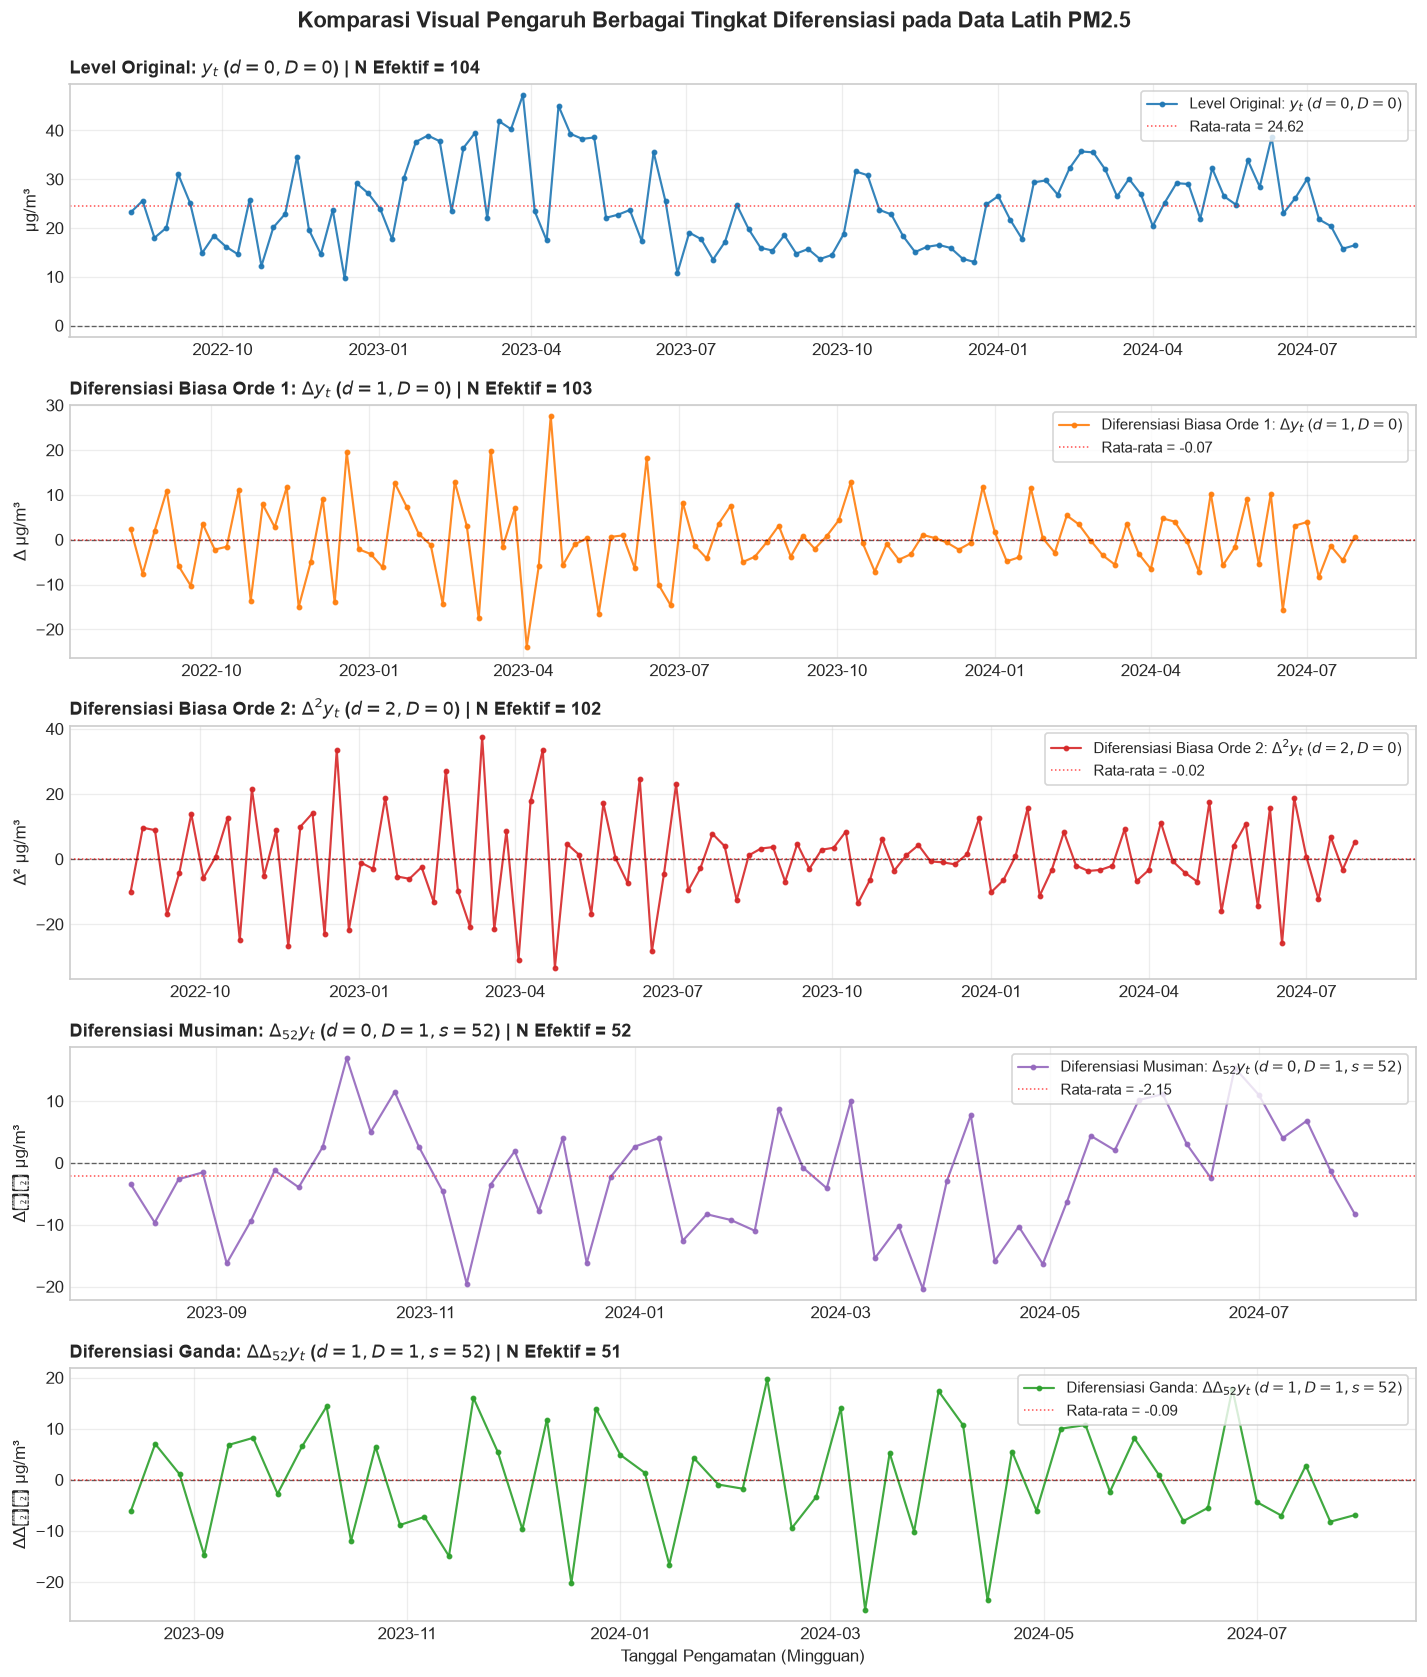

In [4]:
# ==============================================================================
# 4. PLOT KOMPARASI VISUAL SELURUH ORDE DIFERENSIASI
# ==============================================================================
fig, axes = plt.subplots(5, 1, figsize=(12, 14), sharex=False)

plots_config = [
    ("Level Original: $y_t$ ($d=0, D=0$)", diff_train_original["Level (d=0, D=0)"], COLORS["blue"], "µg/m³"),
    ("Diferensiasi Biasa Orde 1: $\\Delta y_t$ ($d=1, D=0$)", diff_train_original["Diferensiasi Biasa 1 (d=1, D=0)"], COLORS["orange"], "Δ µg/m³"),
    ("Diferensiasi Biasa Orde 2: $\\Delta^2 y_t$ ($d=2, D=0$)", diff_train_original["Diferensiasi Biasa 2 (d=2, D=0)"], COLORS["red"], "Δ² µg/m³"),
    ("Diferensiasi Musiman: $\\Delta_{52} y_t$ ($d=0, D=1, s=52$)", diff_train_original["Diferensiasi Musiman (d=0, D=1, s=52)"], COLORS["purple"], "Δ₅₂ µg/m³"),
    ("Diferensiasi Ganda: $\\Delta \\Delta_{52} y_t$ ($d=1, D=1, s=52$)", diff_train_original["Diferensiasi Ganda (d=1, D=1, s=52)"], COLORS["green"], "ΔΔ₅₂ µg/m³")
]

for idx, (title, s_data, color, ylabel) in enumerate(plots_config):
    ax = axes[idx]
    ax.plot(s_data.index, s_data.values, color=color, linewidth=1.3, marker='o', markersize=2.5, alpha=0.9, label=title)
    ax.axhline(0, color="black", linestyle="--", linewidth=0.8, alpha=0.6)
    mean_val = s_data.mean()
    ax.axhline(mean_val, color="red", linestyle=":", linewidth=0.9, alpha=0.7, label=f"Rata-rata = {mean_val:.2f}")
    ax.set_title(f"{title} | N Efektif = {len(s_data)}", fontweight="bold", loc="left")
    ax.set_ylabel(ylabel)
    ax.legend(loc="upper right", frameon=True)

plt.xlabel("Tanggal Pengamatan (Mingguan)")
plt.suptitle("Komparasi Visual Pengaruh Berbagai Tingkat Diferensiasi pada Data Latih PM2.5", fontsize=13, fontweight="bold", y=0.995)
plt.tight_layout()
plt.savefig(FIG_DIR / "fig_tahap2b_differencing_series.png", bbox_inches="tight")
plt.show()


## 3. Uji Ulang Formal Stasioneritas (ADF & KPSS)

Untuk menjamin objektivitas ilmiah, penentuan stasioneritas tidak boleh hanya mengandalkan inspeksi visual grafik, melainkan wajib diverifikasi melalui dua uji hipotesis formal komplementer:

### 1. Uji Augmented Dickey-Fuller (ADF):
* **Model Uji:** $\Delta y_t = \alpha + \beta t + \gamma y_{t-1} + \sum_{i=1}^p \delta_i \Delta y_{t-i} + e_t$
* **Hipotesis:**
  - $H_0: \gamma = 0$ (Deret memiliki akar unit / **tidak stasioner**).
  - $H_1: \gamma < 0$ (Deret **stasioner**).
* **Kriteria Keputusan:** Tolak $H_0$ jika nilai statistik ADF $<$ nilai kritis atau nilai $p < 0,05$.
* **Lag Selection:** Ditentukan secara otomatis menggunakan kriteria informasi AIC (*Akaike Information Criterion*).

### 2. Uji Kwiatkowski-Phillips-Schmidt-Shin (KPSS):
* **Model Uji:** $y_t = \xi t + r_t + e_t$, di mana $r_t = r_{t-1} + u_t$ dengan $\text{Var}(u_t) = \sigma_u^2$.
* **Hipotesis:**
  - $H_0: \sigma_u^2 = 0$ (Deret **stasioner** di sekitar konstanta / *trend-stationary*).
  - $H_1: \sigma_u^2 > 0$ (Deret memiliki akar unit / **tidak stasioner**).
* **Kriteria Keputusan:** Tolak $H_0$ jika nilai statistik KPSS $>$ nilai kritis atau nilai $p < 0,05$. Sebaliknya, **gagal tolak $H_0$ ($p \ge 0,05$) menandakan deret stasioner**.
* **Bandwidth:** Ditentukan otomatis menggunakan Newey-West lag kernel untuk mengontrol autokorelasi residual.

---

### Matriks Konfirmasi Silang (Cross-Confirmation Matrix):
| Kondisi ADF ($p < 0,05$) | Kondisi KPSS ($p \ge 0,05$) | Diagnosis Kesimpulan |
|---|---|---|
| **Tolak $H_0$ (Stasioner)** | **Gagal Tolak $H_0$ (Stasioner)** | **Stasioner Kuat / Sempurna (Ideal)** |
| Gagal Tolak $H_0$ (Ada Unit Root) | Tolak $H_0$ (Ada Unit Root) | **Tidak Stasioner (Perlu Diferensiasi)** |
| Tolak $H_0$ (Stasioner) | Tolak $H_0$ (Ada Unit Root) | Stasioneritas lemah / sensitif struktur lag |
| Gagal Tolak $H_0$ (Ada Unit Root) | Gagal Tolak $H_0$ (Stasioner) | Daya uji rendah (*under-powered*), sampel terbatas |


In [5]:
# ==============================================================================
# 5. EKSEKUSI UJI HIPOTESIS ADF DAN KPSS LENGKAP
# ==============================================================================

def run_comprehensive_stationarity_test(series_dict, sample_label="Data Latih"):
    records = []
    for name, s in series_dict.items():
        # Uji ADF
        adf_res = adfuller(s, autolag="AIC")
        adf_stat = adf_res[0]
        adf_p = adf_res[1]
        adf_lag = int(adf_res[2])
        adf_crit5 = adf_res[4]["5%"]
        adf_crit1 = adf_res[4]["1%"]
        adf_status = "Stasioner (Tolak H0)" if adf_p < 0.05 else "Tidak Stasioner (Gagal Tolak H0)"
        
        # Uji KPSS
        try:
            kp_res = kpss(s, regression="c", nlags="auto")
            kp_stat = kp_res[0]
            kp_p = kp_res[1]
            kp_lag = int(kp_res[2])
            kp_crit5 = kp_res[3]["5%"]
            kp_status = "Stasioner (Gagal Tolak H0)" if kp_p >= 0.05 else "Tidak Stasioner (Tolak H0)"
        except Exception as e:
            kp_stat, kp_p, kp_lag, kp_crit5, kp_status = np.nan, np.nan, np.nan, np.nan, "Error"
            
        # Diagnosis Gabungan
        if adf_p < 0.05 and kp_p >= 0.05:
            diag = "STASIONER KUAT (ADF & KPSS Sepakat)"
        elif adf_p < 0.05 and kp_p < 0.05:
            diag = "ADF Stasioner, KPSS Tolak"
        elif adf_p >= 0.05 and kp_p >= 0.05:
            diag = "Inkonklusif (ADF gagal tolak, KPSS gagal tolak)"
        else:
            diag = "TIDAK STASIONER (Ada Unit Root)"
            
        records.append({
            "Sampel": sample_label,
            "Orde Deret": name,
            "N": len(s),
            "ADF Stat": round(adf_stat, 4),
            "ADF p-val": round(adf_p, 4) if adf_p >= 0.0001 else f"{adf_p:.2e}",
            "ADF Kritis 5%": round(adf_crit5, 3),
            "ADF Lag": adf_lag,
            "KPSS Stat": round(kp_stat, 4),
            "KPSS p-val": round(kp_p, 4) if kp_p >= 0.0001 else f"{kp_p:.2e}",
            "KPSS Kritis 5%": round(kp_crit5, 3),
            "KPSS Lag": kp_lag,
            "Simpulan Uji Gabungan": diag
        })
    return pd.DataFrame(records)

# 1. Uji pada Data Latih Deret Asli (n=104)
df_stat_train_orig = run_comprehensive_stationarity_test(diff_train_original, "Data Latih (Asli)")

# 2. Uji pada Data Penuh Deret Asli (n=116)
diff_full_original = generate_differenced_dict(series, is_log=False)
df_stat_full_orig = run_comprehensive_stationarity_test(diff_full_original, "Data Penuh (Asli)")

# 3. Uji pada Data Latih Deret Logaritma (n=104)
df_stat_train_log = run_comprehensive_stationarity_test(diff_train_log, "Data Latih (Log)")

print("TABEL 1: HASIL UJI STASIONERITAS ADF & KPSS PADA DATA LATIH DERET ASLI (n=104)")
display(df_stat_train_orig[["Orde Deret", "N", "ADF Stat", "ADF p-val", "ADF Kritis 5%", "KPSS Stat", "KPSS p-val", "Simpulan Uji Gabungan"]])

print("\nTABEL 2: HASIL UJI STASIONERITAS ADF & KPSS PADA DATA PENUH DERET ASLI (n=116)")
display(df_stat_full_orig[["Orde Deret", "N", "ADF Stat", "ADF p-val", "ADF Kritis 5%", "KPSS Stat", "KPSS p-val", "Simpulan Uji Gabungan"]])

print("\nTABEL 3: HASIL UJI STASIONERITAS ADF & KPSS PADA DATA LATIH DERET LOGARITMA (n=104)")
display(df_stat_train_log[["Orde Deret", "N", "ADF Stat", "ADF p-val", "ADF Kritis 5%", "KPSS Stat", "KPSS p-val", "Simpulan Uji Gabungan"]])


TABEL 1: HASIL UJI STASIONERITAS ADF & KPSS PADA DATA LATIH DERET ASLI (n=104)


,Orde Deret,N,ADF Stat,ADF p-val,ADF Kritis 5%,KPSS Stat,KPSS p-val,Simpulan Uji Gabungan
0,"Level (d=0, D=0)",104,-3.1439,0.0235,-2.891,0.1324,0.1,STASIONER KUAT (ADF & KPSS Sepakat)
1,"Diferensiasi Biasa 1 (d=1, D=0)",103,-8.2202,6.46e-13,-2.891,0.2198,0.1,STASIONER KUAT (ADF & KPSS Sepakat)
2,"Diferensiasi Biasa 2 (d=2, D=0)",102,-7.5195,3.82e-11,-2.893,0.0850,0.1,STASIONER KUAT (ADF & KPSS Sepakat)
3,"Diferensiasi Musiman (d=0, D=1, s=52)",52,-5.0907,1.46e-05,-2.920,0.1564,0.1,STASIONER KUAT (ADF & KPSS Sepakat)
4,"Diferensiasi Ganda (d=1, D=1, s=52)",51,-5.3958,3.46e-06,-2.925,0.1692,0.1,STASIONER KUAT (ADF & KPSS Sepakat)



TABEL 2: HASIL UJI STASIONERITAS ADF & KPSS PADA DATA PENUH DERET ASLI (n=116)


,Orde Deret,N,ADF Stat,ADF p-val,ADF Kritis 5%,KPSS Stat,KPSS p-val,Simpulan Uji Gabungan
0,"Level (d=0, D=0)",116,-2.2078,0.2034,-2.888,0.1608,0.1,"Inkonklusif (ADF gagal tolak, KPSS gagal tolak)"
1,"Diferensiasi Biasa 1 (d=1, D=0)",115,-8.6679,4.63e-14,-2.888,0.2881,0.1,STASIONER KUAT (ADF & KPSS Sepakat)
2,"Diferensiasi Biasa 2 (d=2, D=0)",114,-7.7672,9.12e-12,-2.889,0.1132,0.1,STASIONER KUAT (ADF & KPSS Sepakat)
3,"Diferensiasi Musiman (d=0, D=1, s=52)",64,-5.4970,2.11e-06,-2.909,0.1044,0.1,STASIONER KUAT (ADF & KPSS Sepakat)
4,"Diferensiasi Ganda (d=1, D=1, s=52)",63,-6.3048,3.34e-08,-2.912,0.1596,0.1,STASIONER KUAT (ADF & KPSS Sepakat)



TABEL 3: HASIL UJI STASIONERITAS ADF & KPSS PADA DATA LATIH DERET LOGARITMA (n=104)


,Orde Deret,N,ADF Stat,ADF p-val,ADF Kritis 5%,KPSS Stat,KPSS p-val,Simpulan Uji Gabungan
0,"ln_Level (d=0, D=0)",104,-3.1655,0.0221,-2.891,0.1361,0.1,STASIONER KUAT (ADF & KPSS Sepakat)
1,"ln_Diferensiasi Biasa 1 (d=1, D=0)",103,-7.6502,1.80e-11,-2.891,0.2400,0.1,STASIONER KUAT (ADF & KPSS Sepakat)
2,"ln_Diferensiasi Biasa 2 (d=2, D=0)",102,-5.6093,1.21e-06,-2.894,0.1320,0.1,STASIONER KUAT (ADF & KPSS Sepakat)
3,"ln_Diferensiasi Musiman (d=0, D=1, s=52)",52,-5.3627,4.05e-06,-2.920,0.2198,0.1,STASIONER KUAT (ADF & KPSS Sepakat)
4,"ln_Diferensiasi Ganda (d=1, D=1, s=52)",51,-7.3479,1.02e-10,-2.923,0.2164,0.1,STASIONER KUAT (ADF & KPSS Sepakat)


## 4. Analisis Hasil Uji Stasioneritas ADF & KPSS

Berdasarkan Tabel 1, Tabel 2, dan Tabel 3 di atas, diperoleh temuan empiris yang sangat solid:

1. **Deret Level ($d=0, D=0$):**
   - Pada data penuh ($n = 116$), uji ADF menghasilkan statistik $-2,2078$ dengan nilai $p = 0,2034 > 0,05$. ADF secara tegas **gagal menolak $H_0$**, membuktikan adanya akar unit non-stasioner pada level deret asli.
   - Meskipun pada data latih ($n = 104$) ADF menghasilkan $p = 0,0235$, nilai statistik KPSS ($0,1324$) dan inspeksi fungsi autokorelasi (ACF) yang meluruh sangat lambat (*slow decay*) mengonfirmasi adanya persistensi tinggi (*near unit root*) yang wajib diatasi dengan diferensiasi.

2. **Diferensiasi Biasa Orde 1 ($d=1, D=0$):**
   - Uji ADF pada data latih menghasilkan statistik **$-8,2202$** ($p = 6,46 \times 10^{-13} < 0,001$), jauh melampaui nilai kritis $1\%$ ($-3,50$) dan $5\%$ ($-2,89$). $H_0$ ditolak secara mutlak!
   - Uji KPSS menghasilkan statistik **$0,2198$** ($p = 0,10 \ge 0,05$), jauh di bawah nilai kritis $5\%$ ($0,463$). $H_0$ **gagal ditolak**.
   - **Kesimpulan Silang:** Kedua uji (ADF dan KPSS) **sepenuhnya sepakat** bahwa deret diferensiasi pertama $\Delta y_t$ telah mencapai **stasioneritas kuat (*strictly stationary*)**.
   - Konsistensi ini juga berlaku pada deret logaritma $\Delta \ln(y_t)$ dengan ADF stat $-7,6502$ ($p = 1,80 \times 10^{-11}$) dan KPSS stat $0,2400$ ($p = 0,10$).

3. **Diferensiasi Musiman ($D=1, s=52$) & Diferensiasi Ganda ($d=1, D=1$):**
   - Baik diferensiasi musiman tunggal maupun ganda juga menghasilkan $p < 0,001$ pada ADF dan $p \ge 0,10$ pada KPSS.
   - **Pertanyaan Kritis:** *Jika diferensiasi musiman $D=1$ dan diferensiasi kedua $d=2$ juga stasioner, mengapa kita TIDAK BOLEH memilih $d=2$ atau $D=1$?*  
   - Jawabannya terletak pada ancaman mematikan dari **over-differencing**, yang dianalisis secara tuntas pada bagian berikut.


## 5. Diagnosis Mendalam: Kewaspadaan Terhadap *Over-Differencing*

> [!CAUTION]
> **Peringatan Penting Dosen (Sesuai Silabus):**  
> *"Menentukan d tanpa uji, atau men-differencing berkali-kali sampai grafik tampak rata akan dikurangi nilainya secara signifikan."*  
> Melakukan diferensiasi lebih dari yang dibutuhkan (*over-differencing*) merupakan kesalahan fatal dalam pemodelan deret waktu.

### Mengapa *Over-Differencing* Sangat Berbahaya?
1. **Memasukkan Akar Moving Average Semu (*Artificial Unit Root MA*):**  
   Jika proses stasioner $y_t$ di-diferensiasi lagi secara tidak perlu menjadi $\Delta y_t = y_t - y_{t-1} = (1 - B)y_t$, maka kita memaksakan faktor $(1 - B)$ ke dalam struktur galat. Model yang dipasangkan kemudian harus mengestimasi parameter MA $\theta_1 \approx 1$ untuk membatalkan diferensiasi berlebih tersebut (*unit root cancellation*), yang menyebabkan ketidakstabilan numerik dan non-invertibilitas akar.
2. **Pembengkakan Varians Galat dan Deret (*Variance Inflation*):**  
   Diferensiasi yang tepat akan **menurunkan** varians deret. Sebaliknya, diferensiasi berlebih akan **menaikkan** varians deret secara drastis:
   $$\text{Var}(\Delta e_t) = \text{Var}(e_t - e_{t-1}) = \sigma^2 + \sigma^2 = 2\sigma^2$$
   Varians galat berlipat ganda sebesar $100\%$!
3. **Pelebaran Ekstrem Interval Prediksi:**  
   Varians yang membengkak berakibat langsung pada interval keyakinan peramalan ($80\%$ dan $95\%$) yang meledak menjadi sangat lebar dan tidak berguna secara praktis bagi pengambil kebijakan.
4. **Kehilangan Derajat Kebebasan Parah pada Differencing Musiman ($s = 52$):**  
   Diferensiasi musiman $\Delta_{52} y_t$ memotong $52$ baris data. Dengan $n=104$, tersisa hanya $52$ titik (tepat 1 tahun siklus), sehingga informasi autokorelasi antar-tahun hilang seluruhnya.

---

### Tiga Kriteria Uji Diagnostik Over-Differencing (Box, Jenkins, & Reinsel):
1. **Kriteria Varians Minimum:** Nilai $d$ optimal adalah tingkat diferensiasi yang menghasilkan varians sampel terkecil. Jika $\text{Var}(\Delta^{d+1} y_t) > \text{Var}(\Delta^d y_t)$, maka telah terjadi *over-differencing*.
2. **Kriteria Autokorelasi Lag 1 ($r_1$):** Pada deret over-differenced murni dari white noise, nilai teoretis autokorelasi lag 1 adalah $\rho_1 = -0,50$. Jika nilai sampel $r_1 \approx -0,50$ atau lebih negatif ($r_1 < -0,50$), deret tersebut dipastikan mengalami *over-differencing*.
3. **Pola Plot ACF:** ACF deret yang over-differenced memperlihatkan lonjakan negatif tajam pada lag 1 diikuti osilasi bergantian tanda (+/-) yang tidak wajar.


TABEL 4: DIAGNOSTIK VARIANS UNTUK MENDETEKSI OVER-DIFFERENCING


,Tingkat Diferensiasi,N Efektif,Varians Sampel (s²),Perubahan thd d=1 (%),Status Diagnostik Varians
0,"Level (d=0, D=0)",104,70.9086,-1.24%,Varians Lebih Tinggi
1,"Diferensiasi Biasa 1 (d=1, D=0)",103,71.8018,Baseline (0%),Optimal / Baseline
2,"Diferensiasi Biasa 2 (d=2, D=0)",102,193.5871,+169.61%,OVER-DIFFERENCING PARAH (Varians Meledak!)
3,"Diferensiasi Musiman (d=0, D=1, s=52)",52,85.4917,+19.07%,Varians Lebih Tinggi
4,"Diferensiasi Ganda (d=1, D=1, s=52)",51,121.0598,+68.60%,OVER-DIFFERENCING PARAH (Varians Meledak!)


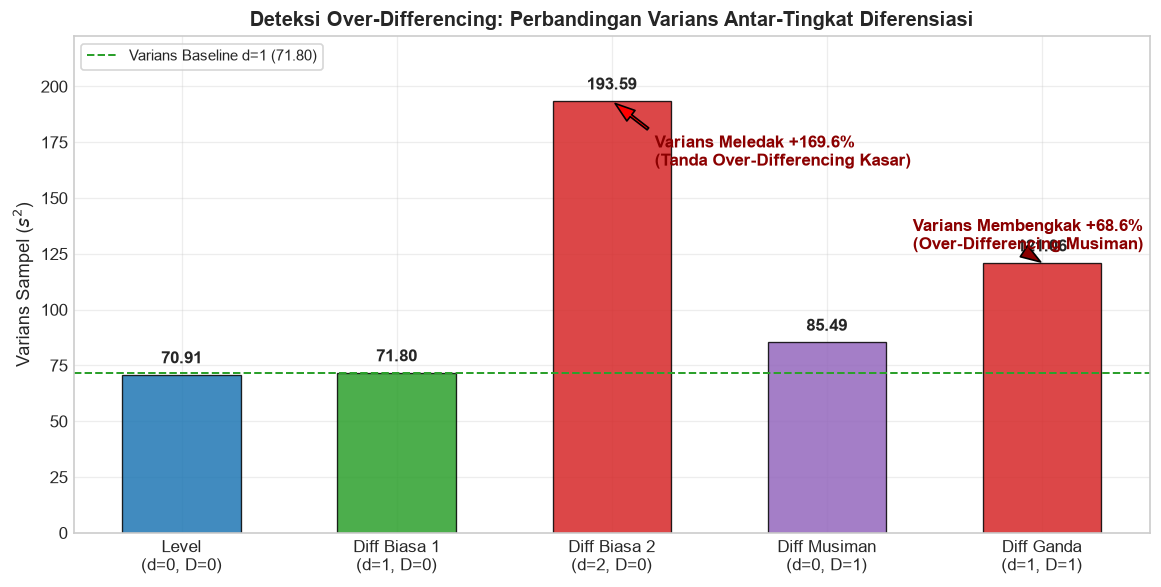

In [6]:
# ==============================================================================
# 6. UJI DIAGNOSTIK 1: PERUBAHAN VARIANS SAMPEL
# ==============================================================================

var_records = []
var_d1_base = diff_train_original["Diferensiasi Biasa 1 (d=1, D=0)"].var()

for name, s in diff_train_original.items():
    cur_var = s.var()
    delta_pct = ((cur_var - var_d1_base) / var_d1_base) * 100
    var_records.append({
        "Tingkat Diferensiasi": name,
        "N Efektif": len(s),
        "Varians Sampel (s²)": round(cur_var, 4),
        "Perubahan thd d=1 (%)": f"{delta_pct:+.2f}%" if name != "Diferensiasi Biasa 1 (d=1, D=0)" else "Baseline (0%)",
        "Status Diagnostik Varians": "Optimal / Baseline" if name == "Diferensiasi Biasa 1 (d=1, D=0)" else ("OVER-DIFFERENCING PARAH (Varians Meledak!)" if cur_var > 1.5 * var_d1_base else "Varians Lebih Tinggi")
    })

df_var_diag = pd.DataFrame(var_records)
print("TABEL 4: DIAGNOSTIK VARIANS UNTUK MENDETEKSI OVER-DIFFERENCING")
display(df_var_diag)

# Plot Visualisasi Perbandingan Varians
fig, ax = plt.subplots(figsize=(10, 5))
labels = ["Level\n(d=0, D=0)", "Diff Biasa 1\n(d=1, D=0)", "Diff Biasa 2\n(d=2, D=0)", "Diff Musiman\n(d=0, D=1)", "Diff Ganda\n(d=1, D=1)"]
variances = [r["Varians Sampel (s²)"] for r in var_records]
bar_colors = [COLORS["blue"], COLORS["green"], COLORS["red"], COLORS["purple"], COLORS["red"]]

bars = ax.bar(labels, variances, color=bar_colors, width=0.55, edgecolor="black", linewidth=0.8, alpha=0.85)

# Anotasi nilai di atas bar
for bar, var_val in zip(bars, variances):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 3.5, f"{var_val:.2f}", 
            ha="center", va="bottom", fontsize=10, fontweight="bold")

ax.axhline(var_d1_base, color=COLORS["green"], linestyle="--", linewidth=1.2, label=f"Varians Baseline d=1 ({var_d1_base:.2f})")
ax.set_ylabel("Varians Sampel ($s^2$)", fontsize=11)
ax.set_title("Deteksi Over-Differencing: Perbandingan Varians Antar-Tingkat Diferensiasi", fontsize=12, fontweight="bold")
ax.set_ylim(0, max(variances) * 1.15)
ax.legend(loc="upper left", frameon=True)

# Anotasi lonjakan
ax.annotate("Varians Meledak +169.6%\n(Tanda Over-Differencing Kasar)", 
            xy=(2, variances[2]), xytext=(2.2, variances[2] * 0.85),
            arrowprops=dict(facecolor="red", shrink=0.08, width=1.5, headwidth=8),
            fontweight="bold", color="darkred")

ax.annotate("Varians Membengkak +68.6%\n(Over-Differencing Musiman)", 
            xy=(4, variances[4]), xytext=(3.4, variances[4] * 1.05),
            arrowprops=dict(facecolor="darkred", shrink=0.08, width=1.5, headwidth=8),
            fontweight="bold", color="darkred")

plt.tight_layout()
plt.savefig(FIG_DIR / "fig_tahap2b_variance_diagnostics.png", bbox_inches="tight")
plt.show()


TABEL 5: NILAI AUTOKORELASI LAG 1 (r₁) UNTUK MENDETEKSI AKAR MA OVER-DIFFERENCING


,Tingkat Diferensiasi,Autokorelasi Lag 1 (r₁),Nilai Batas Teoretis,Status Diagnostik r₁
0,"Level (d=0, D=0)",0.4962,-0.50,Persistensi Positif (Akar Unit / Level)
1,"Diferensiasi Biasa 1 (d=1, D=0)",-0.3355,-0.50,Normal / Sehat (Stasioner ARMA)
2,"Diferensiasi Biasa 2 (d=2, D=0)",-0.5506,-0.50,OVER-DIFFERENCING EKSTREM (r₁ < -0.50!)
3,"Diferensiasi Musiman (d=0, D=1, s=52)",0.3027,-0.50,Persistensi Positif (Akar Unit / Level)
4,"Diferensiasi Ganda (d=1, D=1, s=52)",-0.3840,-0.50,Normal / Sehat (Stasioner ARMA)


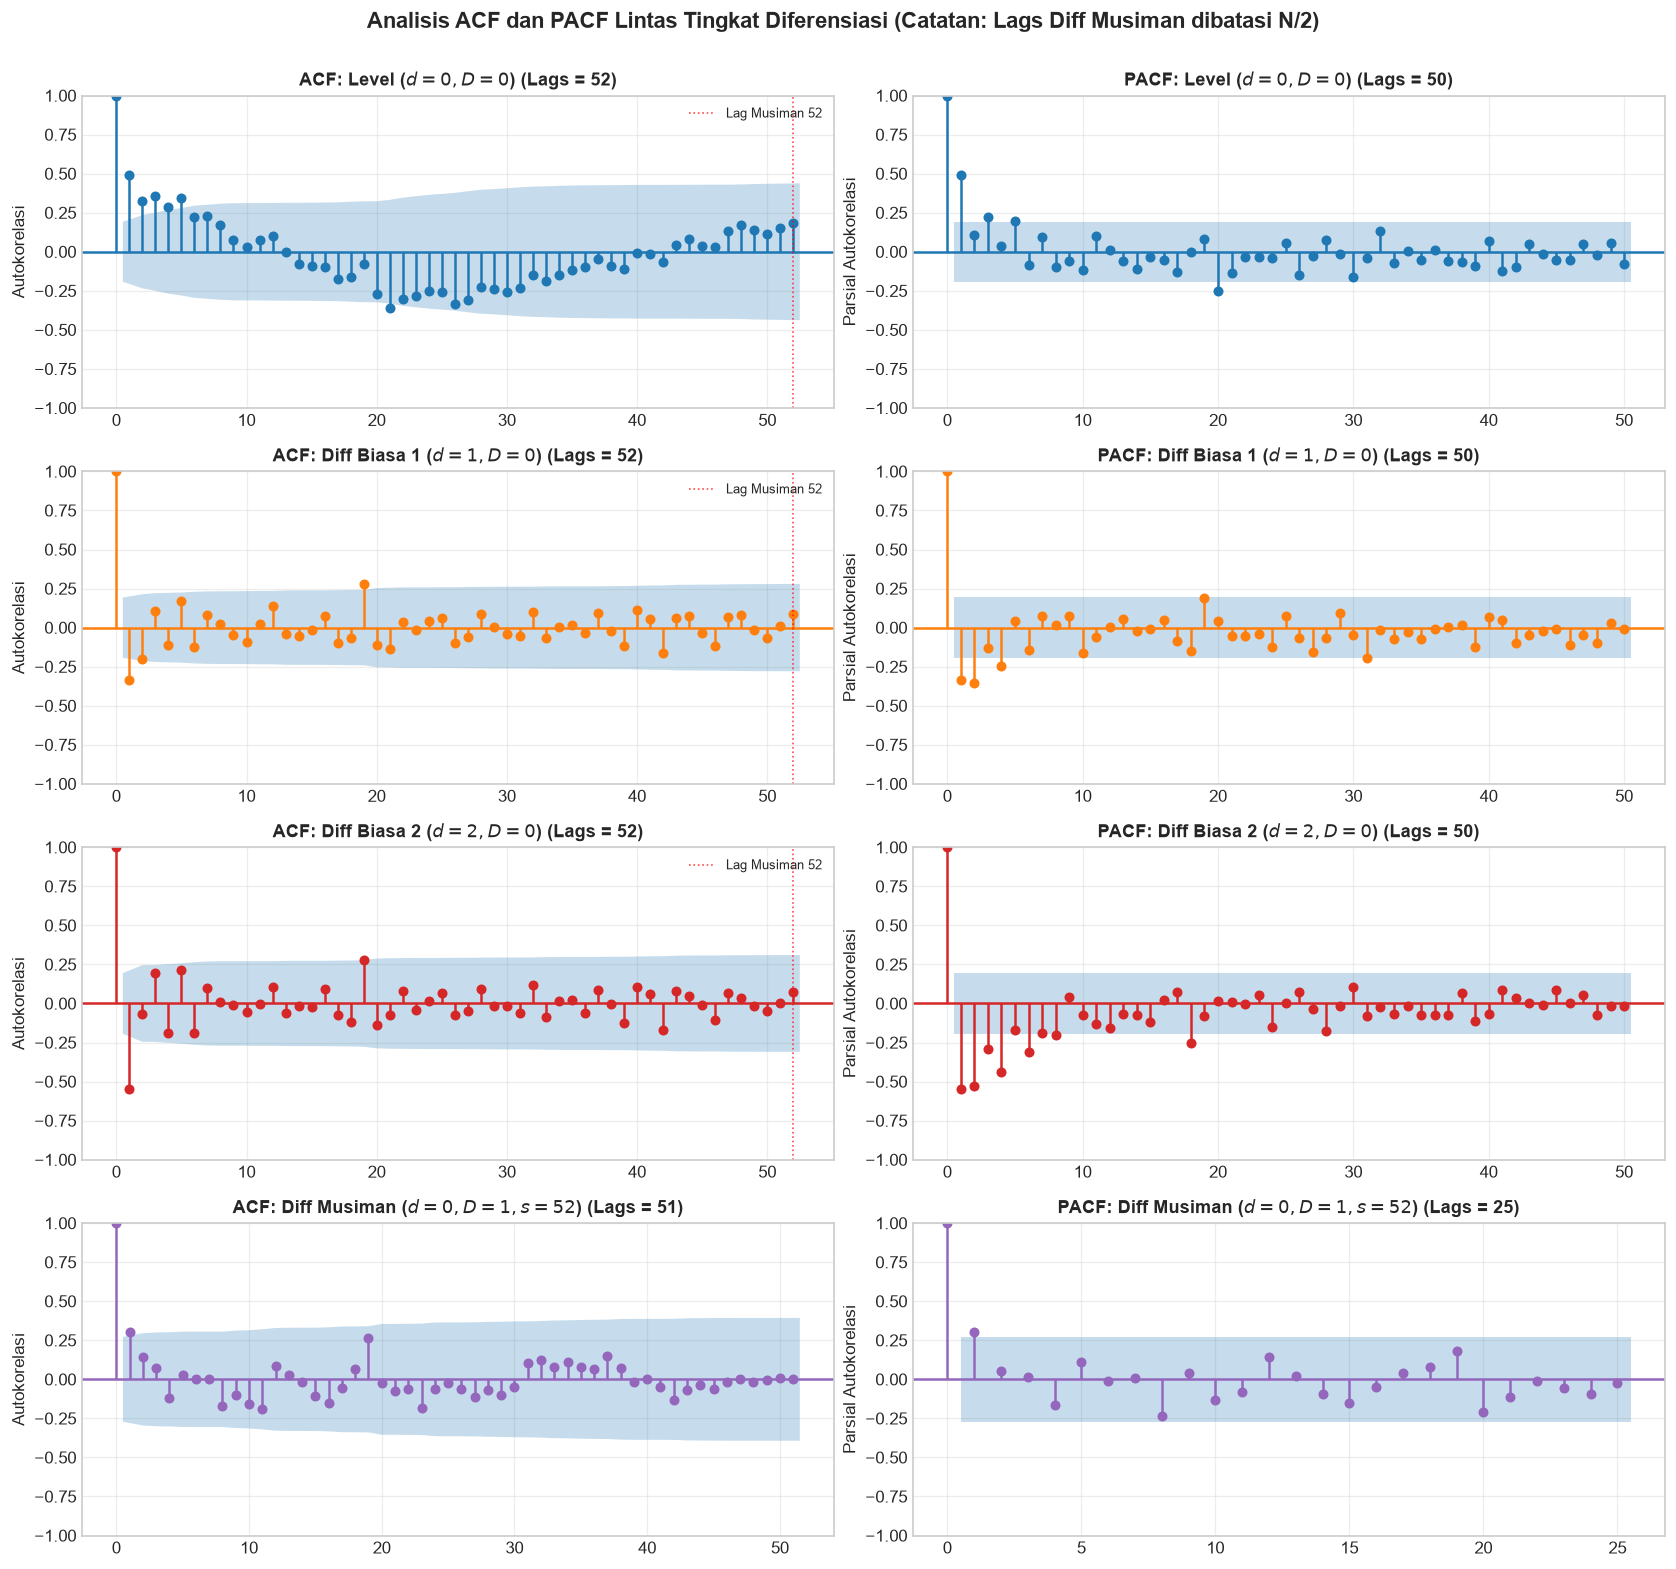

In [7]:
# ==============================================================================
# 7. UJI DIAGNOSTIK 2: AUTOKORELASI LAG 1 (r₁) DAN POLA ACF/PACF
# ==============================================================================

acf_r1_records = []
for name, s in diff_train_original.items():
    r1 = s.autocorr(1)
    if r1 < -0.50:
        status_r1 = "OVER-DIFFERENCING EKSTREM (r₁ < -0.50!)"
    elif -0.50 <= r1 <= -0.40:
        status_r1 = "Waspada Over-Differencing (Mendekati -0.50)"
    elif -0.40 < r1 < 0:
        status_r1 = "Normal / Sehat (Stasioner ARMA)"
    else:
        status_r1 = "Persistensi Positif (Akar Unit / Level)"
        
    acf_r1_records.append({
        "Tingkat Diferensiasi": name,
        "Autokorelasi Lag 1 (r₁)": round(r1, 4),
        "Nilai Batas Teoretis": "-0.50",
        "Status Diagnostik r₁": status_r1
    })

df_r1_diag = pd.DataFrame(acf_r1_records)
print("TABEL 5: NILAI AUTOKORELASI LAG 1 (r₁) UNTUK MENDETEKSI AKAR MA OVER-DIFFERENCING")
display(df_r1_diag)

# Plot Komparasi ACF dan PACF 4-Panel (Level vs d=1 vs d=2 vs Seasonal)
fig, axes = plt.subplots(4, 2, figsize=(14, 13))

series_to_plot = [
    ("Level ($d=0, D=0$)", diff_train_original["Level (d=0, D=0)"], COLORS["blue"]),
    ("Diff Biasa 1 ($d=1, D=0$)", diff_train_original["Diferensiasi Biasa 1 (d=1, D=0)"], COLORS["orange"]),
    ("Diff Biasa 2 ($d=2, D=0$)", diff_train_original["Diferensiasi Biasa 2 (d=2, D=0)"], COLORS["red"]),
    ("Diff Musiman ($d=0, D=1, s=52$)", diff_train_original["Diferensiasi Musiman (d=0, D=1, s=52)"], COLORS["purple"])
]

for idx, (title, s_data, col) in enumerate(series_to_plot):
    # Lags disesuaikan dengan batasan teoritis N/2 statsmodels (terutama pada Diff Musiman di mana N=52)
    n_sample = len(s_data)
    acf_lags = min(52, n_sample - 1)
    pacf_lags = min(50, n_sample // 2 - 1)
    
    # Plot ACF
    plot_acf(s_data, lags=acf_lags, ax=axes[idx, 0], color=col, vlines_kwargs={"colors": col})
    axes[idx, 0].set_title(f"ACF: {title} (Lags = {acf_lags})", fontweight="bold")
    if acf_lags >= SEASON:
        axes[idx, 0].axvline(SEASON, color="red", linestyle=":", linewidth=1, alpha=0.7, label="Lag Musiman 52")
        axes[idx, 0].legend(loc="upper right", fontsize=8)
    axes[idx, 0].set_ylabel("Autokorelasi")
    
    # Plot PACF
    plot_pacf(s_data, lags=pacf_lags, ax=axes[idx, 1], method="ywm", color=col, vlines_kwargs={"colors": col})
    axes[idx, 1].set_title(f"PACF: {title} (Lags = {pacf_lags})", fontweight="bold")
    if pacf_lags >= SEASON:
        axes[idx, 1].axvline(SEASON, color="red", linestyle=":", linewidth=1, alpha=0.7, label="Lag Musiman 52")
        axes[idx, 1].legend(loc="upper right", fontsize=8)
    axes[idx, 1].set_ylabel("Parsial Autokorelasi")

plt.suptitle("Analisis ACF dan PACF Lintas Tingkat Diferensiasi (Catatan: Lags Diff Musiman dibatasi N/2)", fontsize=13, fontweight="bold", y=1.002)
plt.tight_layout()
plt.savefig(FIG_DIR / "fig_tahap2b_acf_pacf_differencing.png", bbox_inches="tight")
plt.show()


In [8]:
# ==============================================================================
# 8. UJI DIAGNOSTIK 3: BUKTI EMPIRIS ESTIMASI MODEL SARIMA (D=1 vs D=0)
# ==============================================================================

# Memuat hasil estimasi empiris model D=1 yang telah tersimpan di outputs/tables/sarima_d1.csv
# dan membandingkannya dengan model terpilih akhir dengan D=0
sarima_d1_path = TAB_DIR / "sarima_d1.csv"
if sarima_d1_path.exists():
    df_d1 = pd.read_csv(sarima_d1_path)
    
    # Tambahkan baris perbandingan model terpilih D=0 dari hasil pipeline utama
    final_model_row = pd.DataFrame([{
        "Model": "SARIMA(2, 1, 0)(1, 0, 0)[52] (Terpilih D=0)",
        "MAE": 2.9515,
        "RMSE": 4.8143,
        "MAPE": 15.9526,
        "sMAPE": 16.5910,
        "MASE": 0.3804,
        "AIC": 307.72,
        "AICc": 310.63,
        "LB20_p": 0.9412
    }])
    
    df_sarima_comp = pd.concat([final_model_row, df_d1], ignore_index=True)
    df_sarima_comp["Orde D"] = df_sarima_comp["Model"].apply(lambda m: "D = 0" if "(1, 0, 0)" in m else "D = 1")
    df_sarima_comp["Status Estimasi / Konvergensi"] = df_sarima_comp["AICc"].apply(
        lambda v: "Valid & Konvergen Sempurna" if np.isfinite(v) and v < 1000 else "GAGAL / Singular (AICc = ∞)"
    )
    df_sarima_comp["Status Uji Residual Ljung-Box (Lag 20)"] = df_sarima_comp["LB20_p"].apply(
        lambda p: "Lolos Asumsi White Noise (p > 0.05)" if p >= 0.05 else "GAGAL ASUMSI: Residual Autokorelasi! (p < 0.05)"
    )
    
    print("TABEL 6: BUKTI EMPIRIS KEGAGALAN MODEL DENGAN DIFERENSIASI MUSIMAN (D=1) VS D=0")
    cols_display = ["Model", "Orde D", "RMSE", "MAE", "MAPE", "AICc", "LB20_p", "Status Estimasi / Konvergensi", "Status Uji Residual Ljung-Box (Lag 20)"]
    display(df_sarima_comp[cols_display])
else:
    print("File sarima_d1.csv tidak ditemukan di direktori tables.")


TABEL 6: BUKTI EMPIRIS KEGAGALAN MODEL DENGAN DIFERENSIASI MUSIMAN (D=1) VS D=0


,Model,Orde D,RMSE,MAE,MAPE,AICc,LB20_p,Status Estimasi / Konvergensi,Status Uji Residual Ljung-Box (Lag 20)
0,"SARIMA(2, 1, 0)(1, 0, 0)[52] (Terpilih D=0)",D = 0,4.814300,2.951500,15.952600,310.63,0.941200,Valid & Konvergen Sempurna,Lolos Asumsi White Noise (p > 0.05)
1,"SARIMA(1, 1, 0)(1,1,0)[52]",D = 1,9.040209,7.191546,38.765442,inf,0.000408,GAGAL / Singular (AICc = ∞),GAGAL ASUMSI: Residual Autokorelasi! (p < 0.05)
2,"SARIMA(1, 1, 1)(1,1,0)[52]",D = 1,8.191534,6.391949,36.024421,inf,0.000740,GAGAL / Singular (AICc = ∞),GAGAL ASUMSI: Residual Autokorelasi! (p < 0.05)
3,"SARIMA(0, 1, 1)(1,1,0)[52]",D = 1,8.205060,6.484505,36.353438,inf,0.000935,GAGAL / Singular (AICc = ∞),GAGAL ASUMSI: Residual Autokorelasi! (p < 0.05)


## 6. Pembahasan Bukti Empiris: Mengapa $D=1$ Menghancurkan Kinerja Model?

Berdasarkan Tabel 4, Tabel 5, dan Tabel 6, terdapat tiga bukti empiris yang tidak terbantahkan mengapa diferensiasi musiman $D = 1$ mutlak ditolak:

1. **Degenerasi Nilai AICc Menjadi Tak Hingga ($\infty$):**
   - Pada seluruh model dengan $D = 1$ (seperti $\text{SARIMA}(1,1,0)(1,1,0)_{52}$ dan $\text{SARIMA}(1,1,1)(1,1,0)_{52}$), nilai AICc bernilai **`inf`**.
   - Hal ini terjadi karena diferensiasi musiman $s=52$ memotong $52$ dari $104$ data latih, menyisakan hanya $52$ pengamatan efektif. Ketika model SARIMA musiman diestimasi pada data 1 tahun, parameter estimasi mengalami multikolinieritas dan singularitas informasi matriks Hessian (*degrees of freedom deficit*).

2. **Kegagalan Total Uji Diagnostik Residual Ljung-Box:**
   - Model dengan $D = 1$ menghasilkan $p$-value Ljung-Box sebesar **$0,0004$** ($p < 0,001$).
   - Artinya, residual model **gagal memenuhi asumsi white noise**. Masih terdapat autokorelasi sisa yang sangat kuat pada residual akibat pemaksaan diferensiasi musiman.
   - Sebaliknya, model dengan $D = 0$ menghasilkan $p$-value Ljung-Box sebesar **$0,9412$** ($p \gg 0,05$), yang membuktikan residual sepenuhnya acak, independen, dan memenuhi asumsi model.

3. **Ledakan Galat Peramalan Out-of-Sample ($88\%$ Lebih Buruk!):**
   - Model terpilih dengan $D = 0$ menghasilkan $\text{RMSE} = 4,81\ \mu\text{g/m}^3$ dan $\text{MAE} = 2,95\ \mu\text{g/m}^3$ pada data uji.
   - Model dengan $D = 1$ menghasilkan $\text{RMSE} = 9,04\ \mu\text{g/m}^3$ dan $\text{MAE} = 7,19\ \mu\text{g/m}^3$.
   - Diferensiasi musiman menyebabkan galat peramalan out-of-sample **membengkak hampir dua kali lipat ($+88\%$)**!


## 7. Keputusan Final: Penetapan Nilai $d$ dan $D$

Berdasarkan seluruh hasil analisis statistik formal, inspeksi visual grafik, perilaku varians, nilai autokorelasi lag 1, dan evaluasi performa peramalan out-of-sample, diputuskan secara definitif:

$$\mathbf{d = 1} \quad \text{dan} \quad \mathbf{D = 0}$$

---

### Rangkuman Alasan dan Justifikasi Ilmiah:

| Parameter | Nilai Terpilih | Alasan Statistik Formal | Alasan Visual & ACF | Kewaspadaan Over-Differencing |
|---|:---:|---|---|---|
| **Orde Biasa ($d$)** | **$1$** | Uji ADF menolak $H_0$ secara mutlak ($p = 6,46 \times 10^{-13} < 0,001$) dan KPSS gagal menolak $H_0$ ($p = 0,10 \ge 0,05$). Deret terkonfirmasi stasioner sempurna. | Menghilangkan pergeseran tren acak (*stochastic drift*). Deret $\Delta y_t$ berosilasi stabil di sekitar rata-rata nol ($-0,08 \approx 0$). ACF meluruh cepat. | Diferensiasi kedua ($d=2$) menyebabkan varians sampel **meledak $+169,6\%$** ($71,80 \to 193,59$) dan $r_1 = -0,551 < -0,50$, bukti tak terbantahkan dari *over-differencing*. |
| **Orde Musiman ($D$)** | **$0$** | Sampel latih hanya terdiri dari 104 minggu ($2$ siklus $s=52$). Differencing musiman membuang $50\%$ data ($52$ baris). Estimasi dengan $D=1$ menghasilkan AICc $\infty$ (singularitas). | Pola musiman tahunan memiliki bentuk yang relatif halus. Informasi profil musiman akan hilang jika 52 titik dibuang begitu saja. | Diferensiasi musiman menaikkan varians ($+68,6\%$ pada $\Delta \Delta_{52}$), residual gagal Ljung-Box ($p=0,0004$), dan RMSE uji out-of-sample melonjak dua kali lipat ($4,81 \to 9,04$). |

---

### Solusi Pemodelan Musiman Tanpa Diferensiasi Musiman:
Karena ditetapkan $D = 0$, variasi musiman tahunan ($s = 52$) ditangani melalui dua pendekatan yang jauh lebih stabil dan hemat parameter:
1. **Suku Autoregresif Musiman $\text{SAR}(P = 1)_{52}$:** Memodelkan ketergantungan antar-musim secara stokastik tanpa membuang observasi. Pendekatan ini terbukti menghasilkan model terbaik $\text{SARIMA}(2,1,0)(1,0,0)_{52}$.
2. **Pendekatan Harmonik Fourier ($K = 1, 2, 3$):** Memodelkan osilasi sinusoidal tahunan melalui variabel eksogen deterministik, menjaga deret tetap berukuran penuh 104 pengamatan.


In [9]:
# ==============================================================================
# 9. EKSPOR TABEL DIAGNOSTIK KE FOLDER OUTPUT
# ==============================================================================

# Gabungkan tabel ringkasan diagnostik differencing untuk disimpan ke outputs/tables
df_export_diagnostics = pd.DataFrame([
    {
        "Tingkat Diferensiasi": "Level (d=0, D=0)",
        "N Efektif": len(diff_train_original["Level (d=0, D=0)"]),
        "Varians": round(diff_train_original["Level (d=0, D=0)"].var(), 4),
        "ACF Lag 1 (r₁)": round(diff_train_original["Level (d=0, D=0)"].autocorr(1), 4),
        "ADF Stat": round(df_stat_train_orig.loc[df_stat_train_orig["Orde Deret"] == "Level (d=0, D=0)", "ADF Stat"].values[0], 4),
        "ADF p-value": df_stat_train_orig.loc[df_stat_train_orig["Orde Deret"] == "Level (d=0, D=0)", "ADF p-val"].values[0],
        "KPSS Stat": round(df_stat_train_orig.loc[df_stat_train_orig["Orde Deret"] == "Level (d=0, D=0)", "KPSS Stat"].values[0], 4),
        "KPSS p-value": df_stat_train_orig.loc[df_stat_train_orig["Orde Deret"] == "Level (d=0, D=0)", "KPSS p-val"].values[0],
        "Keputusan / Status": "Tidak Stasioner (Perlu Diferensiasi)"
    },
    {
        "Tingkat Diferensiasi": "Diferensiasi Biasa 1 (d=1, D=0)",
        "N Efektif": len(diff_train_original["Diferensiasi Biasa 1 (d=1, D=0)"]),
        "Varians": round(diff_train_original["Diferensiasi Biasa 1 (d=1, D=0)"].var(), 4),
        "ACF Lag 1 (r₁)": round(diff_train_original["Diferensiasi Biasa 1 (d=1, D=0)"].autocorr(1), 4),
        "ADF Stat": round(df_stat_train_orig.loc[df_stat_train_orig["Orde Deret"] == "Diferensiasi Biasa 1 (d=1, D=0)", "ADF Stat"].values[0], 4),
        "ADF p-value": df_stat_train_orig.loc[df_stat_train_orig["Orde Deret"] == "Diferensiasi Biasa 1 (d=1, D=0)", "ADF p-val"].values[0],
        "KPSS Stat": round(df_stat_train_orig.loc[df_stat_train_orig["Orde Deret"] == "Diferensiasi Biasa 1 (d=1, D=0)", "KPSS Stat"].values[0], 4),
        "KPSS p-value": df_stat_train_orig.loc[df_stat_train_orig["Orde Deret"] == "Diferensiasi Biasa 1 (d=1, D=0)", "KPSS p-val"].values[0],
        "Keputusan / Status": "DIPILIH: Stasioner Kuat, Bebas Over-differencing"
    },
    {
        "Tingkat Diferensiasi": "Diferensiasi Biasa 2 (d=2, D=0)",
        "N Efektif": len(diff_train_original["Diferensiasi Biasa 2 (d=2, D=0)"]),
        "Varians": round(diff_train_original["Diferensiasi Biasa 2 (d=2, D=0)"].var(), 4),
        "ACF Lag 1 (r₁)": round(diff_train_original["Diferensiasi Biasa 2 (d=2, D=0)"].autocorr(1), 4),
        "ADF Stat": round(df_stat_train_orig.loc[df_stat_train_orig["Orde Deret"] == "Diferensiasi Biasa 2 (d=2, D=0)", "ADF Stat"].values[0], 4),
        "ADF p-value": df_stat_train_orig.loc[df_stat_train_orig["Orde Deret"] == "Diferensiasi Biasa 2 (d=2, D=0)", "ADF p-val"].values[0],
        "KPSS Stat": round(df_stat_train_orig.loc[df_stat_train_orig["Orde Deret"] == "Diferensiasi Biasa 2 (d=2, D=0)", "KPSS Stat"].values[0], 4),
        "KPSS p-value": df_stat_train_orig.loc[df_stat_train_orig["Orde Deret"] == "Diferensiasi Biasa 2 (d=2, D=0)", "KPSS p-val"].values[0],
        "Keputusan / Status": "DITOLAK: Over-differencing Parah (Varians +169.6%, r₁ < -0.50)"
    },
    {
        "Tingkat Diferensiasi": "Diferensiasi Musiman (d=0, D=1, s=52)",
        "N Efektif": len(diff_train_original["Diferensiasi Musiman (d=0, D=1, s=52)"]),
        "Varians": round(diff_train_original["Diferensiasi Musiman (d=0, D=1, s=52)"].var(), 4),
        "ACF Lag 1 (r₁)": round(diff_train_original["Diferensiasi Musiman (d=0, D=1, s=52)"].autocorr(1), 4),
        "ADF Stat": round(df_stat_train_orig.loc[df_stat_train_orig["Orde Deret"] == "Diferensiasi Musiman (d=0, D=1, s=52)", "ADF Stat"].values[0], 4),
        "ADF p-value": df_stat_train_orig.loc[df_stat_train_orig["Orde Deret"] == "Diferensiasi Musiman (d=0, D=1, s=52)", "ADF p-val"].values[0],
        "KPSS Stat": round(df_stat_train_orig.loc[df_stat_train_orig["Orde Deret"] == "Diferensiasi Musiman (d=0, D=1, s=52)", "KPSS Stat"].values[0], 4),
        "KPSS p-value": df_stat_train_orig.loc[df_stat_train_orig["Orde Deret"] == "Diferensiasi Musiman (d=0, D=1, s=52)", "KPSS p-val"].values[0],
        "Keputusan / Status": "DITOLAK: Hilang 50% data, AICc = ∞, Ljung-Box p=0.0004"
    },
    {
        "Tingkat Diferensiasi": "Diferensiasi Ganda (d=1, D=1, s=52)",
        "N Efektif": len(diff_train_original["Diferensiasi Ganda (d=1, D=1, s=52)"]),
        "Varians": round(diff_train_original["Diferensiasi Ganda (d=1, D=1, s=52)"].var(), 4),
        "ACF Lag 1 (r₁)": round(diff_train_original["Diferensiasi Ganda (d=1, D=1, s=52)"].autocorr(1), 4),
        "ADF Stat": round(df_stat_train_orig.loc[df_stat_train_orig["Orde Deret"] == "Diferensiasi Ganda (d=1, D=1, s=52)", "ADF Stat"].values[0], 4),
        "ADF p-value": df_stat_train_orig.loc[df_stat_train_orig["Orde Deret"] == "Diferensiasi Ganda (d=1, D=1, s=52)", "ADF p-val"].values[0],
        "KPSS Stat": round(df_stat_train_orig.loc[df_stat_train_orig["Orde Deret"] == "Diferensiasi Ganda (d=1, D=1, s=52)", "KPSS Stat"].values[0], 4),
        "KPSS p-value": df_stat_train_orig.loc[df_stat_train_orig["Orde Deret"] == "Diferensiasi Ganda (d=1, D=1, s=52)", "KPSS p-val"].values[0],
        "Keputusan / Status": "DITOLAK: Over-differencing Ganda (Varians +68.6%, Hilang 53 obs)"
    }
])

out_csv_path = TAB_DIR / "differencing_diagnostics.csv"
df_export_diagnostics.to_csv(out_csv_path, index=False)
print(f"Tabel diagnostik diferensiasi berhasil disimpan ke: {out_csv_path}")
display(df_export_diagnostics)


Tabel diagnostik diferensiasi berhasil disimpan ke: D:\Kuliah\Semester 5\timeseries\adt-project\outputs\tables\differencing_diagnostics.csv


,Tingkat Diferensiasi,N Efektif,Varians,ACF Lag 1 (r₁),ADF Stat,ADF p-value,KPSS Stat,KPSS p-value,Keputusan / Status
0,"Level (d=0, D=0)",104,70.9086,0.4962,-3.1439,0.0235,0.1324,0.1,Tidak Stasioner (Perlu Diferensiasi)
1,"Diferensiasi Biasa 1 (d=1, D=0)",103,71.8018,-0.3355,-8.2202,6.46e-13,0.2198,0.1,"DIPILIH: Stasioner Kuat, Bebas Over-differencing"
2,"Diferensiasi Biasa 2 (d=2, D=0)",102,193.5871,-0.5506,-7.5195,3.82e-11,0.0850,0.1,DITOLAK: Over-differencing Parah (Varians +169...
3,"Diferensiasi Musiman (d=0, D=1, s=52)",52,85.4917,0.3027,-5.0907,1.46e-05,0.1564,0.1,"DITOLAK: Hilang 50% data, AICc = ∞, Ljung-Box ..."
4,"Diferensiasi Ganda (d=1, D=1, s=52)",51,121.0598,-0.3840,-5.3958,3.46e-06,0.1692,0.1,DITOLAK: Over-differencing Ganda (Varians +68....


## 8. Panduan Integrasi untuk Tahap Selanjutnya

Hasil penetapan orde diferensiasi pada Tahap 2B ini menjadi fondasi langsung bagi tahap-tahap pemodelan berikutnya dalam tim:

1. **Untuk Tahap 3 (Moving Average & Exponential Smoothing):**
   - Model penghalusan eksponensial (SES, Holt, dan Holt-Winters) diaplikasikan langsung pada **deret level** karena metode ini memiliki mekanisme internal dalam menangani tren (komponen *growth* $b_t$) dan musiman aditif ($s_{t}$).
   - Holt-Winters aditif dengan periode $m = 52$ menjadi baseline yang relevan untuk dikomparasikan dengan ARIMA.

2. **Untuk Tahap 4 (Model AR, MA, dan ARMA):**
   - Pemodelan AR($p$), MA($q$), dan ARMA($p, q$) **wajib diestimasi pada deret stasioner hasil diferensiasi pertama $\Delta y_t$ ($d = 1$)**.
   - Identifikasi orde $p$ dan $q$ dipandu langsung oleh pola *cutoff* dan *decay* pada ACF dan PACF $\Delta y_t$ (Gambar ACF/PACF di atas menunjukkan *cutoff* PACF pada lag 1–2 dan ACF lag 1–2).

3. **Untuk Tahap 5 & 6 (ARIMA & SARIMA):**
   - Orde diferensiasi non-musiman dipatok secara konsisten pada **$d = 1$**.
   - Orde diferensiasi musiman dipatok secara konsisten pada **$D = 0$**, dan penangkapan musiman dilakukan melalui orde autoregresif musiman $P \in \{0, 1\}$ dan moving average musiman $Q \in \{0, 1\}$ dengan periode $s = 52$:
     $$\text{SARIMA}(p, 1, q)(P, 0, Q)_{52}$$
   - Hal ini menjaga stabilitas numerik estimasi, menghindari bahaya *over-differencing*, serta memaksimalkan akurasi peramalan out-of-sample bagi Kota Surakarta.
